# Brainiac walkthrough: backpropagation, verified

This notebook trains a network built from scratch in NumPy (`brainiac/`), proves the hand-written gradients are correct, and runs a small controlled experiment. The interactive version is the Streamlit app.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt
from brainiac import NeuralNetwork, load_dataset
from brainiac.gradcheck import gradient_check
from brainiac.curvature import top_eigenvalue, hutchinson_trace
from brainiac.experiments import compare_configs
plt.rcParams['figure.figsize'] = (7, 4)

## 1. Data

Two interleaving half-moons with Gaussian noise; features are standardised with training-set statistics only.

In [2]:
data = load_dataset('Two moons')
print('train', data.X_train.shape, 'test', data.X_test.shape)
print('train mean', data.X_train.mean(axis=1).round(6), 'train std', data.X_train.std(axis=1).round(6))

train (2, 300) test (2, 100)
train mean [-0.  0.] train std [1. 1.]


## 2. Backprop is correct

Compare the analytic gradient with central finite differences, $\frac{L(\theta+\varepsilon e_i)-L(\theta-\varepsilon e_i)}{2\varepsilon}$, for **every** parameter.

In [3]:
net = NeuralNetwork([2, 16, 16, 2], activation='tanh', init='xavier', task='classification', seed=0)
result = gradient_check(net, data.X_train[:, :64], data.Y_train[:, :64])
print(f'overall relative error: {result.overall:.2e}  ({result.checked.size} parameters)')
for name, err in result.per_layer:
    print(f'  {name:3s} {err:.2e}')

overall relative error: 3.27e-10  (354 parameters)
  W1  1.65e-10
  b1  1.65e-09
  W2  4.44e-10
  b2  1.11e-09
  W3  1.85e-10
  b3  1.17e-09


## 3. Train

final training loss 0.0010
test accuracy 98.0%


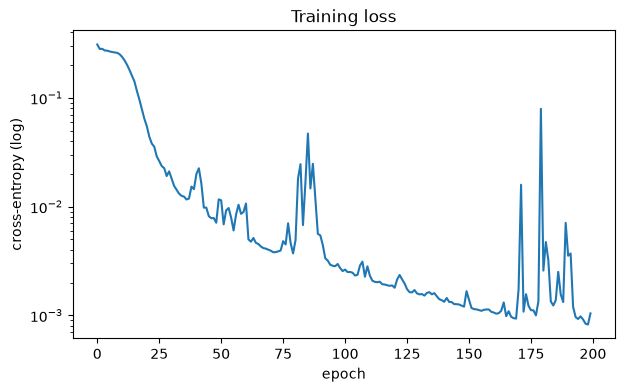

In [4]:
hist = net.fit(data.X_train, data.Y_train, epochs=200, lr=0.01, optimizer='adam', batch_size=32)
print(f'final training loss {hist.loss[-1]:.4f}')
print(f'test accuracy {net.accuracy(data.X_test, data.Y_test):.1%}')
fig, ax = plt.subplots()
ax.semilogy(hist.loss)
ax.set(xlabel='epoch', ylabel='cross-entropy (log)', title='Training loss')
plt.show()

## 4. Curvature at the solution

Power iteration on Hessian-vector products gives $\lambda_{\max}$; gradient descent is only stable for $\eta < 2/\lambda_{\max}$.

In [5]:
g = lambda th: net.flat_grad(th, data.X_train, data.Y_train)
theta = net.get_flat_params()
lam = top_eigenvalue(g, theta)
tr = hutchinson_trace(g, theta, n_samples=50)
print(f'lambda_max = {lam:.3f}  ->  stable SGD step size < {2 / lam:.3f}')
print(f'trace(H) = {tr.mean:.2f} +/- {tr.stderr:.2f}')

lambda_max = 0.932  ->  stable SGD step size < 2.146
trace(H) = 2.02 +/- 0.24


## 5. Experiment: activation x initialisation, 3 seeds each

A deeper, narrower network (four hidden layers of 8) makes the vanishing-gradient effect visible.

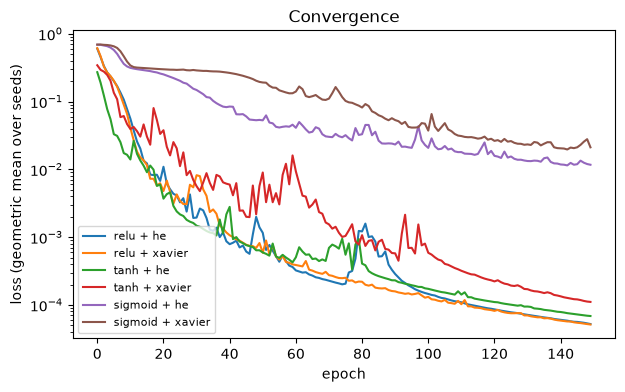

relu + he          final loss 0.0001 +/- 0.0000   test acc 98.0%
relu + xavier      final loss 0.0001 +/- 0.0000   test acc 98.0%
tanh + he          final loss 0.0001 +/- 0.0001   test acc 98.0%
tanh + xavier      final loss 0.0001 +/- 0.0001   test acc 98.0%
sigmoid + he       final loss 0.0729 +/- 0.0991   test acc 96.3%
sigmoid + xavier   final loss 0.0908 +/- 0.1186   test acc 96.0%


In [6]:
runs = compare_configs(data, [8, 8, 8, 8], ['relu', 'tanh', 'sigmoid'], ['he', 'xavier'], seeds=[0, 1, 2],
                       epochs=150, lr=0.01, target=0.1)
fig, ax = plt.subplots()
for r in runs:
    ax.semilogy(np.exp(np.nanmean(np.log(r.curves), axis=0)), label=r.label)
ax.set(xlabel='epoch', ylabel='loss (geometric mean over seeds)', title='Convergence')
ax.legend(fontsize=8)
plt.show()
for r in sorted(runs, key=lambda r: r.final_loss.mean()):
    print(f'{r.label:18s} final loss {r.final_loss.mean():.4f} +/- {r.final_loss.std():.4f}   '
          f'test acc {r.test_metric.mean():.1%}')